In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/Parkinson_Transformer_Project"

folders = [
    "data",
    "processed_data",
    "models",
    "plots",
    "results",
    "attention_maps",
    "shap_analysis"
]

for folder in folders:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
import pandas as pd
import numpy as np

DATA_PATH = "/content/drive/MyDrive/Parkinson_Transformer_Project/data/parkinsons_updrs.data"

df = pd.read_csv(DATA_PATH)

print("Dataset Loaded Successfully!")
print("\nShape of Dataset:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Loaded Successfully!

Shape of Dataset:
(5875, 22)

First 5 Rows:


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,...,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,...,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,...,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,...,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,...,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print("Column Names:\n")
print(df.columns.tolist())

print("\nData Types:\n")
print(df.dtypes)

Column Names:

['subject#', 'age', 'sex', 'test_time', 'motor_UPDRS', 'total_UPDRS', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']

Data Types:

subject#           int64
age                int64
sex                int64
test_time        float64
motor_UPDRS      float64
total_UPDRS      float64
Jitter(%)        float64
Jitter(Abs)      float64
Jitter:RAP       float64
Jitter:PPQ5      float64
Jitter:DDP       float64
Shimmer          float64
Shimmer(dB)      float64
Shimmer:APQ3     float64
Shimmer:APQ5     float64
Shimmer:APQ11    float64
Shimmer:DDA      float64
NHR              float64
HNR              float64
RPDE             float64
DFA              float64
PPE              float64
dtype: object


In [ ]:
raw_backup_path = "/content/drive/MyDrive/Parkinson_Transformer_Project/processed_data/raw_backup.csv"

df.to_csv(raw_backup_path, index=False)

print("Raw backup saved.")

Raw backup saved.


In [ ]:
print("Dataset Statistics")

display(df.describe().T)

Dataset Statistics


,count,mean,std,min,25%,50%,75%,max
subject#,5875.0,21.494128,12.372279,1.000000,10.000000,22.000000,33.000000,42.000000
age,5875.0,64.804936,8.821524,36.000000,58.000000,65.000000,72.000000,85.000000
sex,5875.0,0.317787,0.465656,0.000000,0.000000,0.000000,1.000000,1.000000
test_time,5875.0,92.863722,53.445602,-4.262500,46.847500,91.523000,138.445000,215.490000
motor_UPDRS,5875.0,21.296229,8.129282,5.037700,15.000000,20.871000,27.596500,39.511000
total_UPDRS,5875.0,29.018942,10.700283,7.000000,21.371000,27.576000,36.399000,54.992000
Jitter(%),5875.0,0.006154,0.005624,0.000830,0.003580,0.004900,0.006800,0.099990
Jitter(Abs),5875.0,0.000044,0.000036,0.000002,0.000022,0.000035,0.000053,0.000446
Jitter:RAP,5875.0,0.002987,0.003124,0.000330,0.001580,0.002250,0.003290,0.057540
Jitter:PPQ5,5875.0,0.003277,0.003732,0.000430,0.001820,0.002490,0.003460,0.069560


In [ ]:
missing_values = df.isnull().sum()

missing_df = pd.DataFrame({
    'Feature': missing_values.index,
    'Missing Values': missing_values.values
})

display(missing_df)

print("\nTotal Missing Values:", missing_values.sum())

,Feature,Missing Values
0,subject#,0
1,age,0
2,sex,0
3,test_time,0
4,motor_UPDRS,0
5,total_UPDRS,0
6,Jitter(%),0
7,Jitter(Abs),0
8,Jitter:RAP,0
9,Jitter:PPQ5,0



Total Missing Values: 0


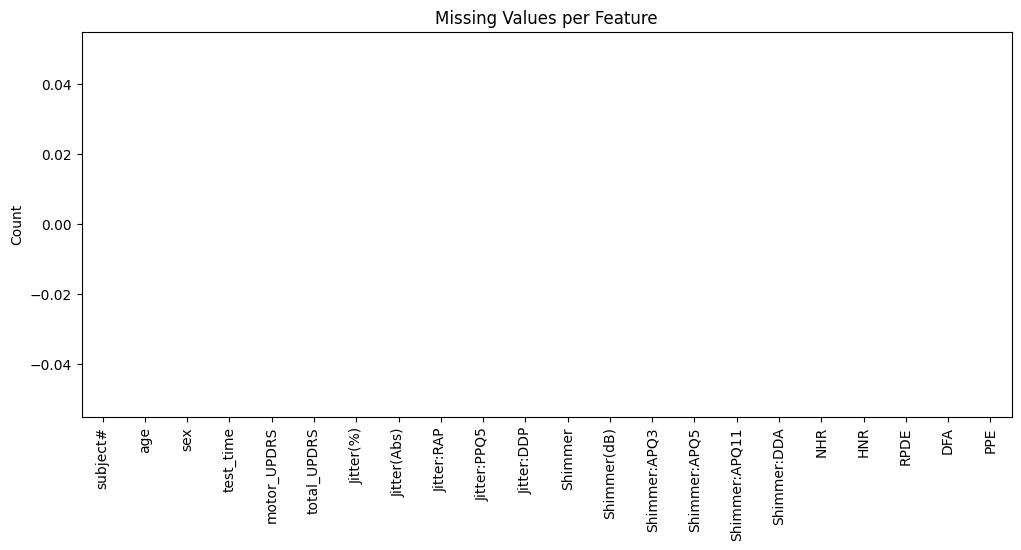

In [ ]:
import matplotlib.pyplot as plt

missing_values.sort_values(ascending=False).plot(
    kind='bar',
    figsize=(12,5)
)

plt.title("Missing Values per Feature")
plt.ylabel("Count")
plt.show()

In [ ]:
duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

Duplicate Rows: 0


In [ ]:
df = df.drop_duplicates()

print("Shape after duplicate removal:")
print(df.shape)

Shape after duplicate removal:
(5875, 22)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5875 entries, 0 to 5874
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subject#       5875 non-null   int64  
 1   age            5875 non-null   int64  
 2   sex            5875 non-null   int64  
 3   test_time      5875 non-null   float64
 4   motor_UPDRS    5875 non-null   float64
 5   total_UPDRS    5875 non-null   float64
 6   Jitter(%)      5875 non-null   float64
 7   Jitter(Abs)    5875 non-null   float64
 8   Jitter:RAP     5875 non-null   float64
 9   Jitter:PPQ5    5875 non-null   float64
 10  Jitter:DDP     5875 non-null   float64
 11  Shimmer        5875 non-null   float64
 12  Shimmer(dB)    5875 non-null   float64
 13  Shimmer:APQ3   5875 non-null   float64
 14  Shimmer:APQ5   5875 non-null   float64
 15  Shimmer:APQ11  5875 non-null   float64
 16  Shimmer:DDA    5875 non-null   float64
 17  NHR            5875 non-null   float64
 18  HNR     

In [ ]:
clean_path = "/content/drive/MyDrive/Parkinson_Transformer_Project/processed_data/cleaned_dataset.csv"

df.to_csv(clean_path, index=False)

print("Cleaned dataset saved.")

Cleaned dataset saved.


In [ ]:
target = "total_UPDRS"

In [ ]:
target = "total_UPDRS"

print(df[target].describe())

count    5875.000000
mean       29.018942
std        10.700283
min         7.000000
25%        21.371000
50%        27.576000
75%        36.399000
max        54.992000
Name: total_UPDRS, dtype: float64


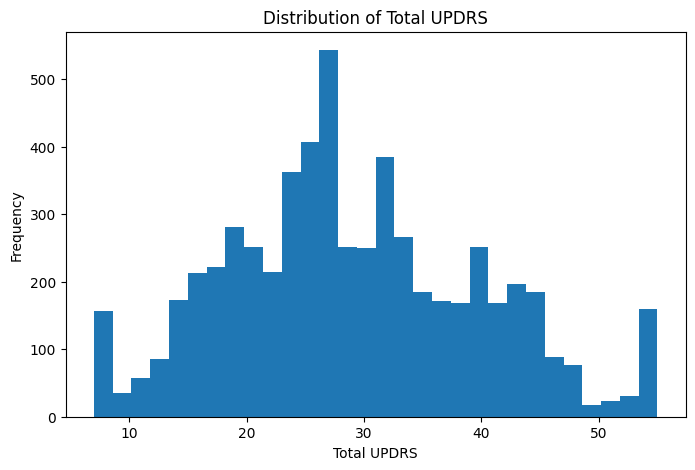

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df[target], bins=30)

plt.title("Distribution of Total UPDRS")
plt.xlabel("Total UPDRS")
plt.ylabel("Frequency")

plt.show()

In [ ]:
target = "total_UPDRS"

X = df.drop(columns=[target])
y = df[target]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (5875, 21)
Target Shape: (5875,)


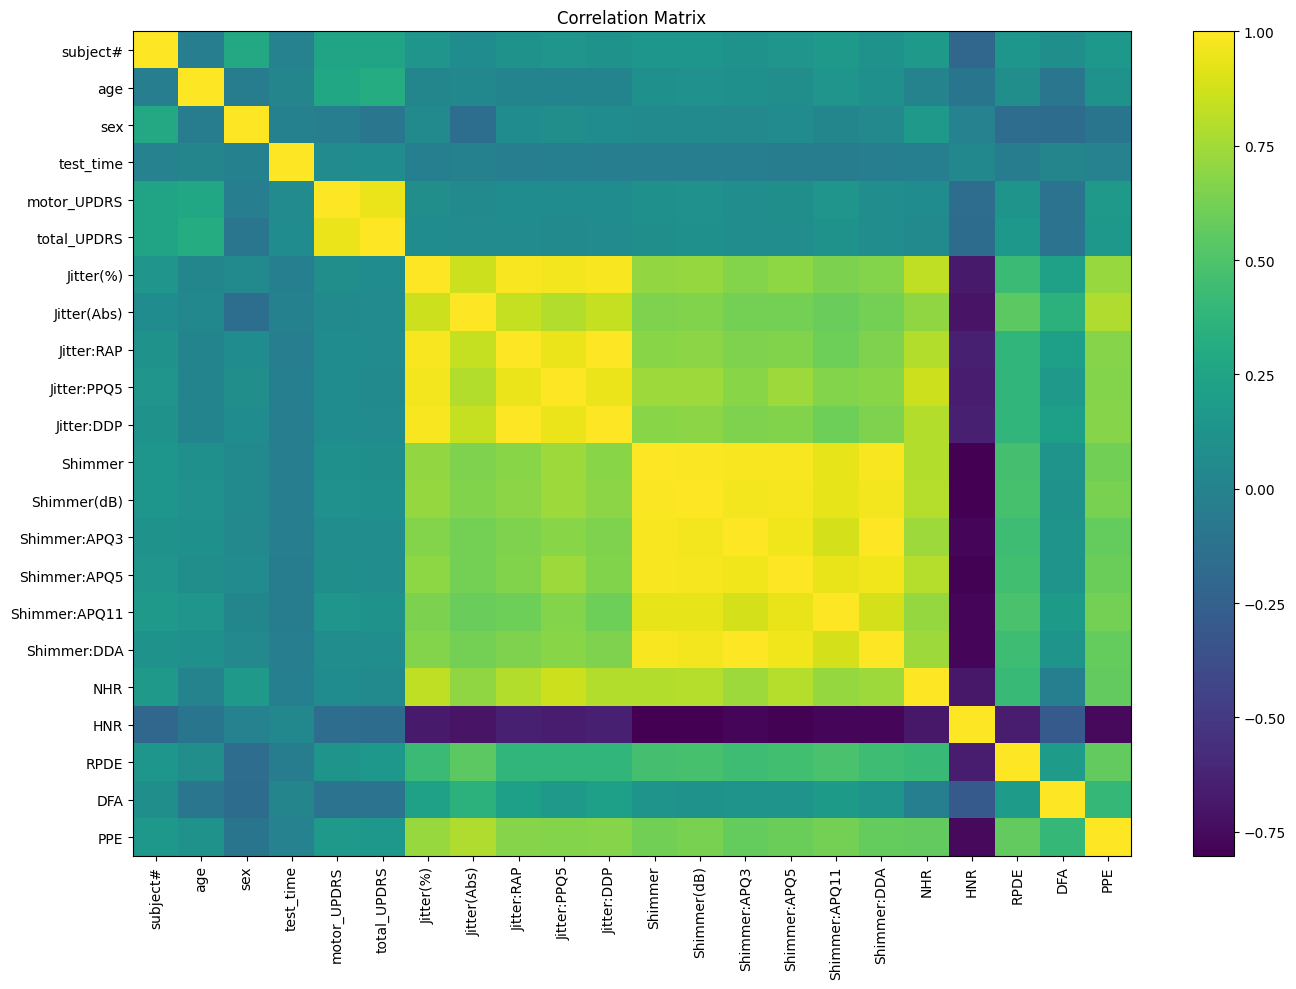

In [ ]:
import matplotlib.pyplot as plt

corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(14,10))

plt.imshow(corr_matrix, aspect='auto')

plt.colorbar()

plt.xticks(range(len(corr_matrix.columns)),
           corr_matrix.columns,
           rotation=90)

plt.yticks(range(len(corr_matrix.columns)),
           corr_matrix.columns)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [ ]:
target_corr = corr_matrix["total_UPDRS"].sort_values(ascending=False)

display(target_corr)

,total_UPDRS
total_UPDRS,1.000000
motor_UPDRS,0.947231
age,0.310290
subject#,0.253643
RPDE,0.156897
PPE,0.156195
Shimmer:APQ11,0.120838
Shimmer(dB),0.098790
Shimmer,0.092141
Shimmer:APQ5,0.083467


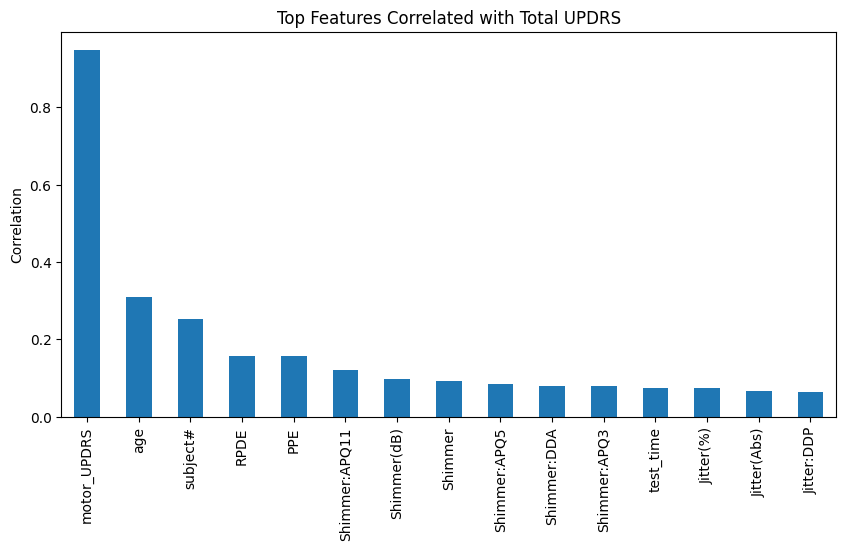

In [ ]:
target_corr.drop("total_UPDRS").head(15).plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Top Features Correlated with Total UPDRS")

plt.ylabel("Correlation")

plt.show()

In [ ]:
numeric_cols = df.select_dtypes(include=['int64','float64']).columns

print("Total Numeric Features:", len(numeric_cols))

Total Numeric Features: 22


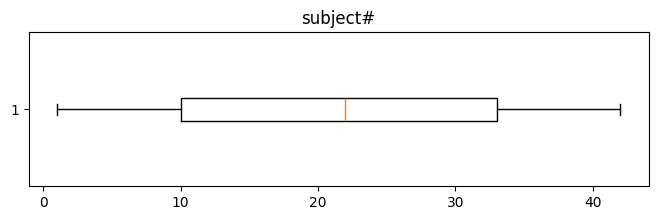

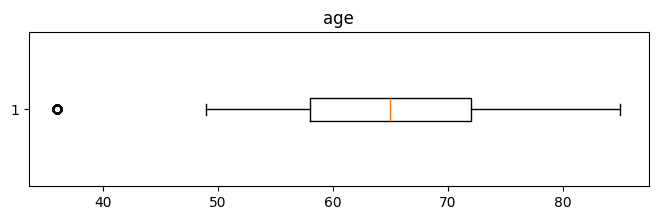

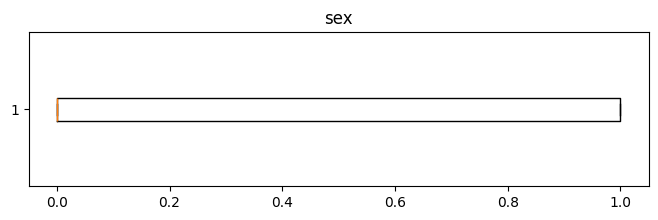

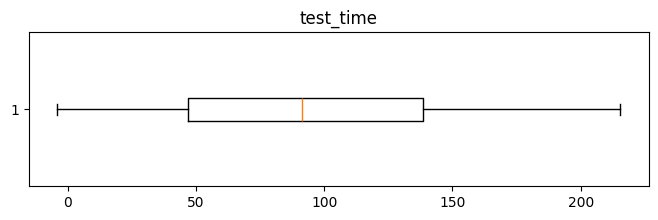

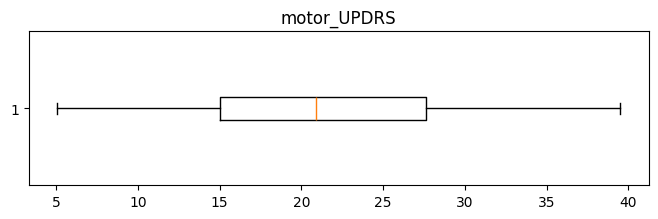

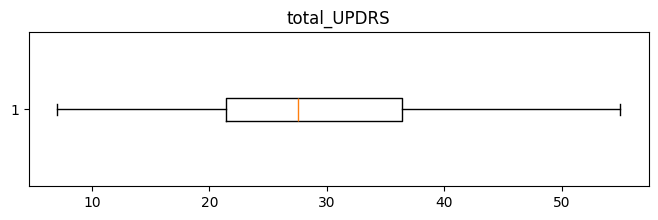

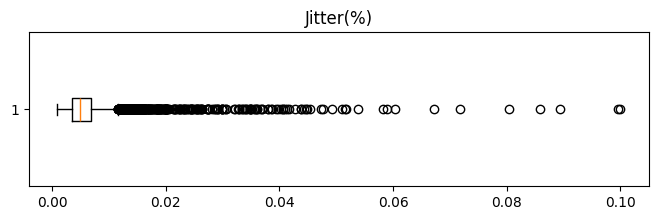

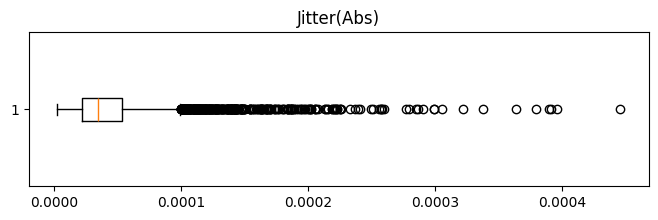

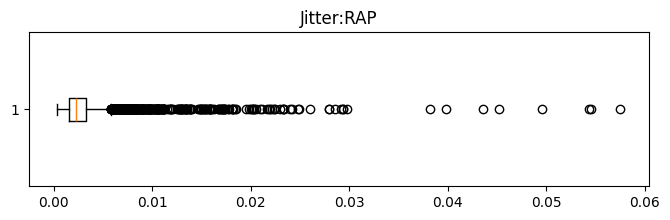

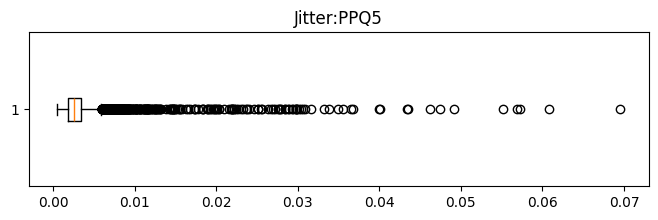

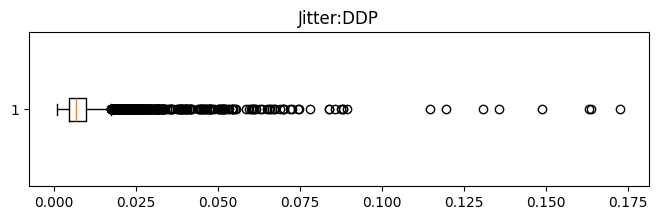

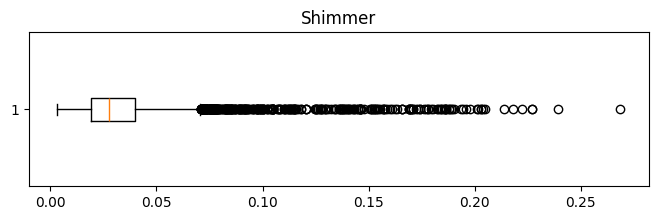

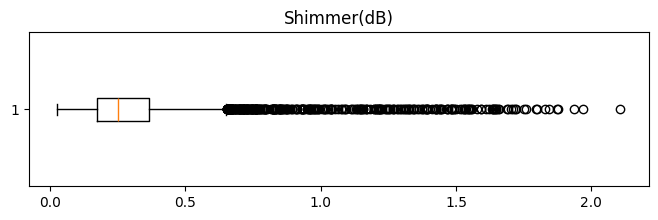

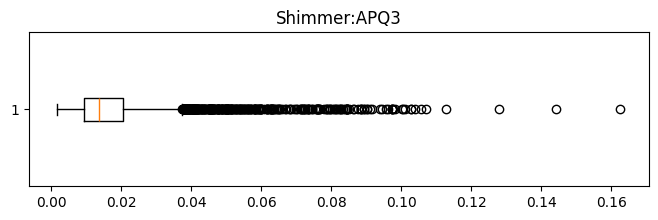

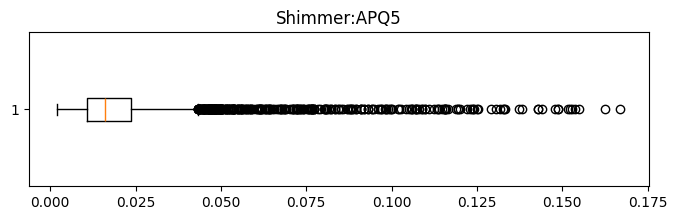

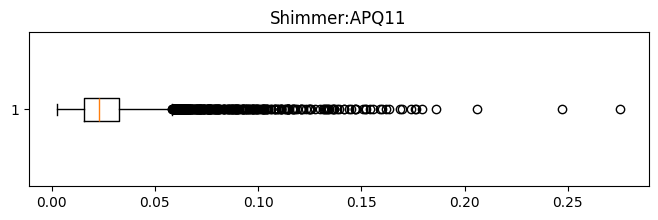

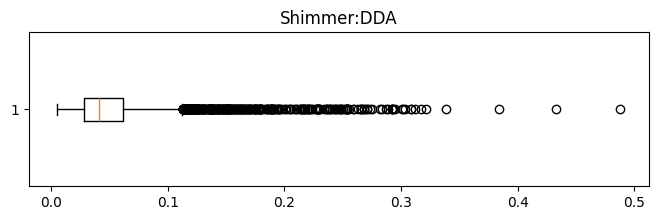

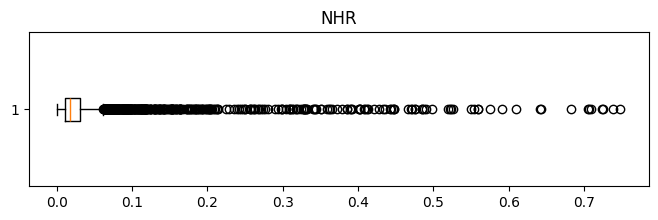

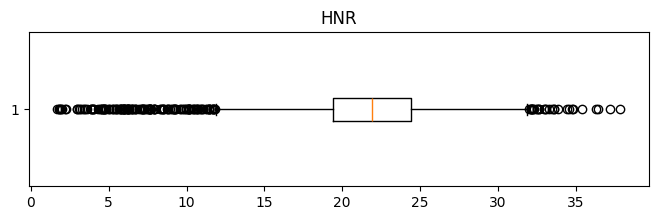

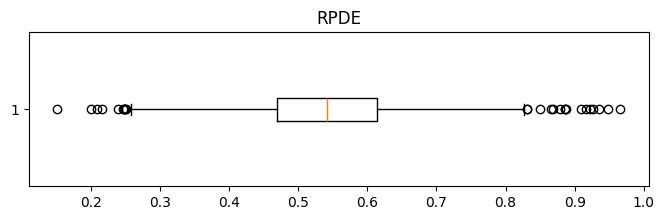

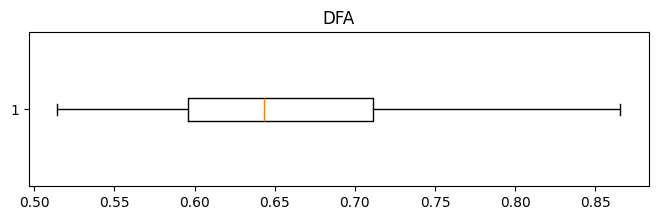

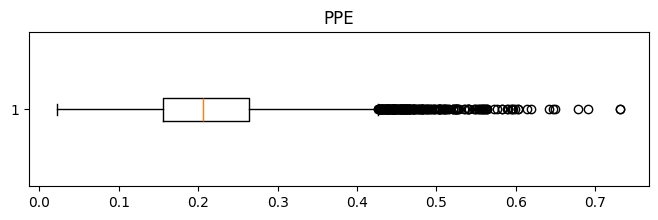

In [ ]:
for col in numeric_cols:

    plt.figure(figsize=(8,2))

    plt.boxplot(df[col], vert=False)

    plt.title(col)

    plt.show()

In [ ]:
outlier_summary = {}

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary[col] = outliers

outlier_df = pd.DataFrame(
    outlier_summary.items(),
    columns=["Feature","Outliers"]
)

display(outlier_df.sort_values("Outliers", ascending=False))

,Feature,Outliers
17,NHR,436
9,Jitter:PPQ5,425
8,Jitter:RAP,414
10,Jitter:DDP,413
6,Jitter(%),398
7,Jitter(Abs),366
11,Shimmer,333
12,Shimmer(dB),332
13,Shimmer:APQ3,332
16,Shimmer:DDA,331


In [ ]:
outlier_df.to_csv(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/outlier_report.csv",
    index=False
)

print("Outlier report saved.")

Outlier report saved.


In [ ]:
# Remove target leakage and patient ID

df_model = df.drop(
    columns=[
        'motor_UPDRS'
    ]
)

print(df_model.shape)

(5875, 21)


In [ ]:
target = "total_UPDRS"

print(df_model.columns)

Index(['subject#', 'age', 'sex', 'test_time', 'total_UPDRS', 'Jitter(%)',
       'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer',
       'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11',
       'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE'],
      dtype='object')


In [ ]:
from sklearn.preprocessing import StandardScaler

feature_columns = [
    col for col in df_model.columns
    if col not in [
        'subject#',
        'total_UPDRS'
    ]
]

print("Number of input features:", len(feature_columns))

scaler = StandardScaler()

scaled_features = scaler.fit_transform(
    df_model[feature_columns]
)

Number of input features: 19


In [ ]:
import joblib

joblib.dump(
    scaler,
    "/content/drive/MyDrive/Parkinson_Transformer_Project/models/scaler.pkl"
)

print("Scaler saved.")

Scaler saved.


In [ ]:
scaled_df = pd.DataFrame(
    scaled_features,
    columns=feature_columns
)

# Add columns needed later

scaled_df["subject#"] = df_model["subject#"].values

scaled_df["total_UPDRS"] = df_model["total_UPDRS"].values

display(scaled_df.head())

,age,sex,test_time,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,Shimmer(dB),...,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE,subject#,total_UPDRS
0,0.815695,-0.682509,-1.632090,0.082905,-0.284242,0.327453,-0.028637,0.328505,-0.324594,-0.351642,...,-0.423356,-0.543466,-0.209704,-0.298721,-0.009205,-1.214066,-1.478500,-0.650658,1,34.398
1,0.815695,-0.682509,-1.500676,-0.560793,-0.756723,-0.533746,-0.476212,-0.534825,-0.534016,-0.573156,...,-0.565592,-0.529955,-0.545153,-0.351965,1.282650,-1.055119,-1.247880,-1.218585,1,34.894
2,0.815695,-0.682509,-1.369410,-0.238944,-0.539382,-0.300038,-0.320767,-0.298983,-0.669115,-0.564469,...,-0.702426,-0.645545,-0.741587,-0.199370,0.318711,-0.784860,-1.540139,-0.103280,1,35.389
3,0.815695,-0.682509,-1.257773,-0.155370,-0.485186,-0.344859,-0.170682,-0.344871,-0.423692,0.069668,...,-0.449763,-0.392849,-0.460787,-0.071754,0.644530,-0.536487,-1.062115,1.237075,1,35.810
4,0.815695,-0.682509,-1.108169,-0.498557,-0.663894,-0.658604,-0.529814,-0.659682,-0.658276,-0.586186,...,-0.651413,-0.464905,-0.783392,-0.343370,1.036305,-0.689195,-1.297953,-0.283954,1,36.375


In [ ]:
scaled_df = scaled_df.sort_values(
    by=["subject#", "test_time"]
).reset_index(drop=True)

display(scaled_df.head())

,age,sex,test_time,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,Jitter:DDP,Shimmer,Shimmer(dB),...,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE,subject#,total_UPDRS
0,0.815695,-0.682509,-1.632090,0.082905,-0.284242,0.327453,-0.028637,0.328505,-0.324594,-0.351642,...,-0.423356,-0.543466,-0.209704,-0.298721,-0.009205,-1.214066,-1.478500,-0.650658,1,34.398
1,0.815695,-0.682509,-1.632090,-0.475441,-0.793688,-0.559358,-0.521773,-0.559369,-0.856085,-0.859821,...,-0.931083,-0.900243,-0.985366,-0.383362,1.456047,-1.664464,-1.808984,-0.534799,1,34.398
2,0.815695,-0.682509,-1.632077,-0.359860,-0.649164,-0.402485,-0.436011,-0.401430,-0.821246,-0.807700,...,-0.818255,-0.823183,-0.876824,-0.022280,1.156331,-0.320497,-1.648467,0.352394,1,34.398
3,0.815695,-0.682509,-1.632053,-0.708382,-0.905693,-0.681014,-0.612897,-0.679958,-1.008604,-1.037900,...,-0.996499,-0.984309,-1.091642,-0.461955,2.113743,-1.280615,-1.516584,-1.365004,1,34.398
4,0.815695,-0.682509,-1.632040,-0.571462,-0.818979,-0.568963,-0.543214,-0.570041,-0.907957,-0.924972,...,-0.911878,-0.930767,-0.949354,-0.288183,1.363522,-1.303393,-1.657635,-0.581908,1,34.399


In [ ]:
SEQUENCE_LENGTH = 5

X_sequences = []
y_sequences = []

for patient in scaled_df["subject#"].unique():

    patient_data = scaled_df[
        scaled_df["subject#"] == patient
    ].reset_index(drop=True)

    patient_features = patient_data.drop(
        columns=[
            "subject#",
            "total_UPDRS"
        ]
    )

    for i in range(
        len(patient_data) - SEQUENCE_LENGTH
    ):

        X_seq = patient_features.iloc[
            i:i+SEQUENCE_LENGTH
        ].values

        y_seq = patient_data.iloc[
            i+SEQUENCE_LENGTH
        ]["total_UPDRS"]

        X_sequences.append(X_seq)
        y_sequences.append(y_seq)

X_sequences = np.array(X_sequences)
y_sequences = np.array(y_sequences)

print("Sequence Shape:", X_sequences.shape)
print("Target Shape:", y_sequences.shape)

Sequence Shape: (5665, 5, 19)
Target Shape: (5665,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_sequences,
    y_sequences,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (4532, 5, 19)
X_test : (1133, 5, 19)
y_train: (4532,)
y_test : (1133,)


In [ ]:
import numpy as np

SAVE_PATH = "/content/drive/MyDrive/Parkinson_Transformer_Project/processed_data/"

np.save(SAVE_PATH + "X_train.npy", X_train)
np.save(SAVE_PATH + "X_test.npy", X_test)
np.save(SAVE_PATH + "y_train.npy", y_train)
np.save(SAVE_PATH + "y_test.npy", y_test)

print("Processed datasets saved successfully.")

Processed datasets saved successfully.


In [ ]:
X_train_rf = X_train.reshape(
    X_train.shape[0],
    -1
)

X_test_rf = X_test.reshape(
    X_test.shape[0],
    -1
)

print("X_train_rf:", X_train_rf.shape)
print("X_test_rf :", X_test_rf.shape)

X_train_rf: (4532, 95)
X_test_rf : (1133, 95)


## RAndom forest , cell 34

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_rf,
    y_train
)

print("Random Forest Training Complete")

Random Forest Training Complete


In [ ]:
import joblib

joblib.dump(
    rf_model,
    "/content/drive/MyDrive/Parkinson_Transformer_Project/models/random_forest.pkl"
)

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [ ]:
rf_predictions = rf_model.predict(X_test_rf)

print("Prediction Shape:", rf_predictions.shape)

print("\nFirst 10 Predictions:")
print(rf_predictions[:10])

Prediction Shape: (1133,)

First 10 Predictions:
[31.70343266 31.80232067 36.52656333 11.80829633 29.27079333 26.44784561
 27.82108341 43.25296667 23.095527   14.60081103]


##cell 37

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("RF MAE :", rf_mae)
print("RF RMSE:", rf_rmse)
print("RF R2  :", rf_r2)

RF MAE : 1.115422596211208
RF RMSE: 1.7735358740084308
RF R2  : 0.9709163337008275


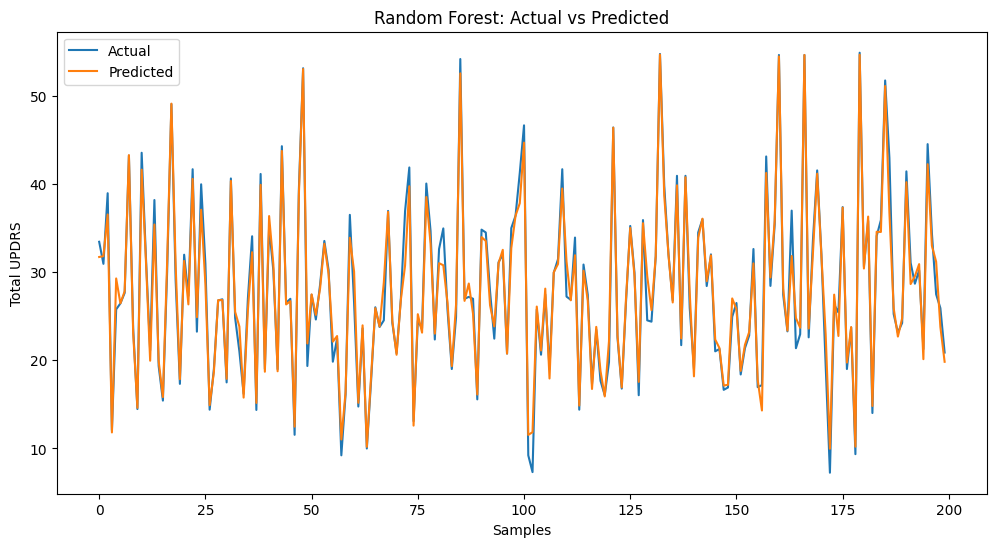

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(
    y_test[:200],
    label="Actual"
)

plt.plot(
    rf_predictions[:200],
    label="Predicted"
)

plt.title("Random Forest: Actual vs Predicted")

plt.xlabel("Samples")

plt.ylabel("Total UPDRS")

plt.legend()

plt.show()

In [ ]:
import pandas as pd

rf_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": rf_predictions
})

rf_results.to_csv(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/rf_predictions.csv",
    index=False
)

print("RF predictions saved successfully.")

RF predictions saved successfully.


In [ ]:
X_sequences.shape

(5665, 5, 19)

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


##lstm

In [ ]:
lstm_model = Sequential([

    LSTM(
        64,
        return_sequences=True,
        input_shape=(5, 19)
    ),

    Dropout(0.2),

    LSTM(
        32,
        return_sequences=False
    ),

    Dropout(0.2),

    Dense(
        16,
        activation='relu'
    ),

    Dense(1)

])

lstm_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 5, 64)          │        21,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 5, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,465 (134.63 KB)

 Trainable params: 34,465 (134.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
lstm_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("LSTM model compiled successfully.")

LSTM model compiled successfully.


In [ ]:
checkpoint_path = "/content/drive/MyDrive/Parkinson_Transformer_Project/models/best_lstm.keras"

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

print("Callbacks configured successfully.")

Callbacks configured successfully.


In [ ]:
history_lstm = lstm_model.fit(

    X_train,
    y_train,

    validation_split=0.2,

    epochs=100,

    batch_size=32,

    callbacks=[
        early_stop,
        checkpoint
    ],

    verbose=1
)

print("LSTM training completed.")

Epoch 1/100
111/114 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 823.7179 - mae: 26.2837
Epoch 1: val_loss improved from None to 195.71352, saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_lstm.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_lstm.keras
114/114 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 603.3528 - mae: 21.3856 - val_loss: 195.7135 - val_mae: 11.0121
Epoch 2/100
104/114 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 155.3263 - mae: 9.7236
Epoch 2: val_loss improved from 195.71352 to 118.00724, saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_lstm.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_lstm.keras
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 134.0668 - mae: 9.1805 - val_loss: 118.0072 - val_mae: 8.7523
Epoch 3/100
104/114 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 120.7729 - mae: 8.8704
Epoch 3: 

In [ ]:
import pandas as pd

history_df = pd.DataFrame(
    history_lstm.history
)

history_df.to_csv(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/lstm_history.csv",
    index=False
)

print("LSTM training history saved successfully.")

LSTM training history saved successfully.


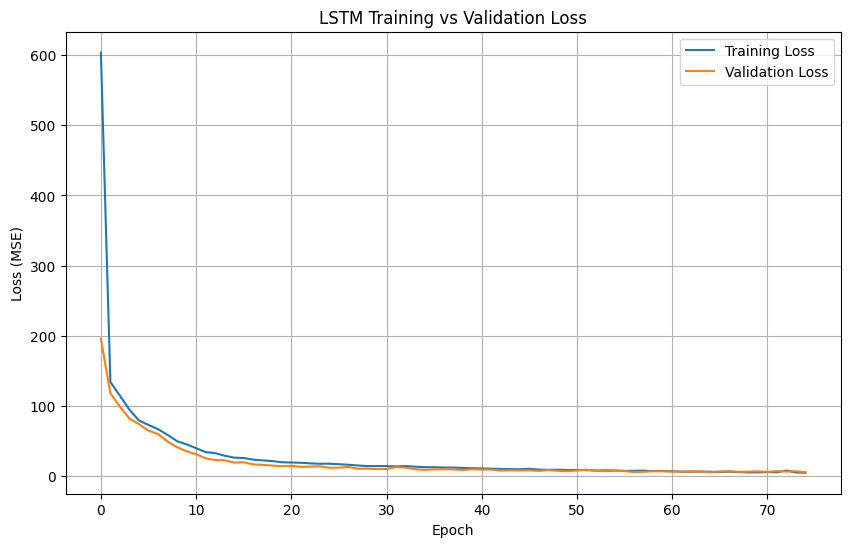

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.plot(
    history_lstm.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_lstm.history['val_loss'],
    label='Validation Loss'
)

plt.title("LSTM Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss (MSE)")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
lstm_predictions = lstm_model.predict(
    X_test
).flatten()

print("Prediction Shape:", lstm_predictions.shape)

print("\nFirst 10 Predictions:")
print(lstm_predictions[:10])

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
Prediction Shape: (1133,)

First 10 Predictions:
[35.996506 30.23983  37.107662 12.516115 26.359138 28.452335 27.255928
 40.98792  22.672398 14.327765]


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

lstm_mae = mean_absolute_error(
    y_test,
    lstm_predictions
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        lstm_predictions
    )
)

lstm_r2 = r2_score(
    y_test,
    lstm_predictions
)

print("LSTM MAE :", lstm_mae)
print("LSTM RMSE:", lstm_rmse)
print("LSTM R2  :", lstm_r2)

LSTM MAE : 1.4991815381864058
LSTM RMSE: 2.644474152649598
LSTM R2  : 0.9353381909158737


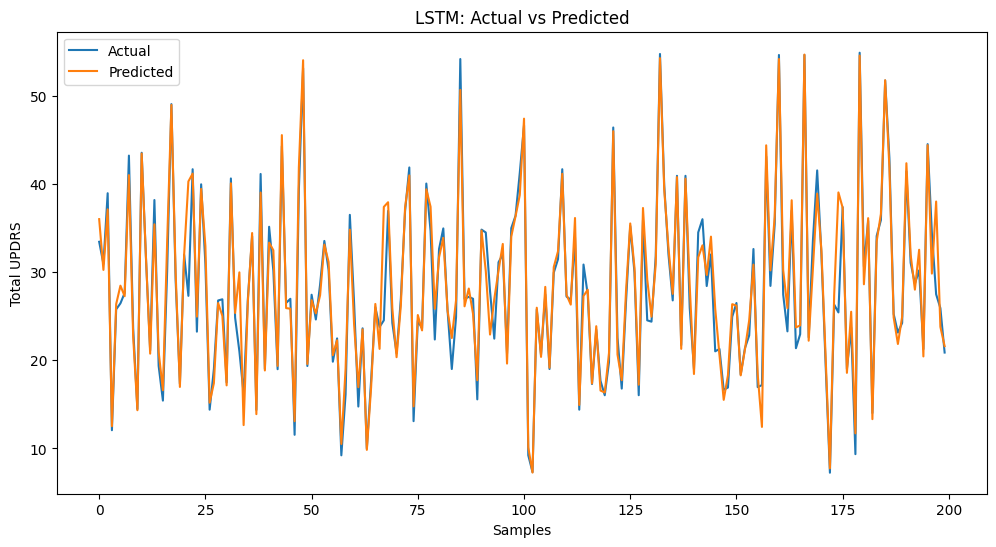

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(
    y_test[:200],
    label="Actual"
)

plt.plot(
    lstm_predictions[:200],
    label="Predicted"
)

plt.title("LSTM: Actual vs Predicted")

plt.xlabel("Samples")

plt.ylabel("Total UPDRS")

plt.legend()

plt.show()

In [ ]:
import pandas as pd

lstm_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": lstm_predictions
})

lstm_results.to_csv(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/lstm_predictions.csv",
    index=False
)

print("LSTM predictions saved successfully.")

LSTM predictions saved successfully.


In [ ]:
X_sequences.shape

(5665, 5, 20)

## transformer

In [ ]:
import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D
)

from tensorflow.keras.models import Model

print("Transformer libraries loaded successfully.")

Transformer libraries loaded successfully.


In [ ]:
def transformer_encoder(inputs,
                        head_size=64,
                        num_heads=4,
                        ff_dim=128,
                        dropout=0.2):

    # Multi-Head Self Attention
    attention_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=head_size
    )(inputs, inputs)

    attention_output = Dropout(dropout)(
        attention_output
    )

    attention_output = LayerNormalization(
        epsilon=1e-6
    )(inputs + attention_output)

    # Feed Forward Network
    ff_output = Dense(
        ff_dim,
        activation="relu"
    )(attention_output)

    ff_output = Dropout(dropout)(
        ff_output
    )

    ff_output = Dense(
        inputs.shape[-1]
    )(ff_output)

    ff_output = LayerNormalization(
        epsilon=1e-6
    )(attention_output + ff_output)

    return ff_output

print("Transformer Encoder Block Created")

Transformer Encoder Block Created


In [ ]:
inputs = Input(shape=(5, 19))

x = transformer_encoder(
    inputs,
    head_size=64,
    num_heads=4,
    ff_dim=128,
    dropout=0.2
)

x = transformer_encoder(
    x,
    head_size=64,
    num_heads=4,
    ff_dim=128,
    dropout=0.2
)

x = GlobalAveragePooling1D()(x)

x = Dense(
    64,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

x = Dense(
    32,
    activation="relu"
)(x)

outputs = Dense(1)(x)

transformer_model = Model(
    inputs=inputs,
    outputs=outputs
)

transformer_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 5, 19)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 5, 19)     │     20,243 │ input_layer_2[0]… │
│ (MultiHeadAttentio… │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 5, 19)     │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 5, 19)     │          0 │ input_layer_2[0]… │
│                     │                   │            │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 5, 19)     │         38 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 5, 128)    │      2,560 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 5, 128)    │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 5, 19)     │      2,451 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 5, 19)     │          0 │ layer_normalizat… │
│                     │                   │            │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 5, 19)     │         38 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 5, 19)     │     20,243 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 5, 19)     │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 5, 19)     │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 5, 19)     │         38 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 5, 128)    │      2,560 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 5, 128)    │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 5, 19)     │      2,451 │ dropout_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 5, 19)     │          0 │ layer_normalizat… │
│                     │                   │            │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 5, 19)     │         38 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 54,053 (211.14 KB)

 Trainable params: 54,053 (211.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
transformer_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("Transformer model compiled successfully.")

Transformer model compiled successfully.


In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

transformer_checkpoint_path = (
    "/content/drive/MyDrive/Parkinson_Transformer_Project/models/best_transformer.keras"
)

transformer_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

transformer_checkpoint = ModelCheckpoint(
    filepath=transformer_checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

print("Transformer callbacks configured successfully.")

Transformer callbacks configured successfully.


In [ ]:
history_transformer = transformer_model.fit(

    X_train,
    y_train,

    validation_split=0.2,

    epochs=100,

    batch_size=32,

    callbacks=[
        transformer_early_stop,
        transformer_checkpoint
    ],

    verbose=1
)

print("Transformer training completed.")

Epoch 1/100
111/114 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 718.6153 - mae: 23.8289
Epoch 1: val_loss improved from None to 114.87189, saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_transformer.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_transformer.keras
114/114 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - loss: 432.9669 - mae: 16.9478 - val_loss: 114.8719 - val_mae: 8.6325
Epoch 2/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 112.8816 - mae: 8.5764
Epoch 2: val_loss improved from 114.87189 to 79.66969, saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_transformer.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_transformer.keras
114/114 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 104.1657 - mae: 8.1988 - val_loss: 79.6697 - val_mae: 7.1457
Epoch 3/100
112/114 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 84

In [ ]:
import pandas as pd

history_transformer_df = pd.DataFrame(
    history_transformer.history
)

history_transformer_df.to_csv(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/transformer_history.csv",
    index=False
)

print("Transformer training history saved successfully.")

Transformer training history saved successfully.


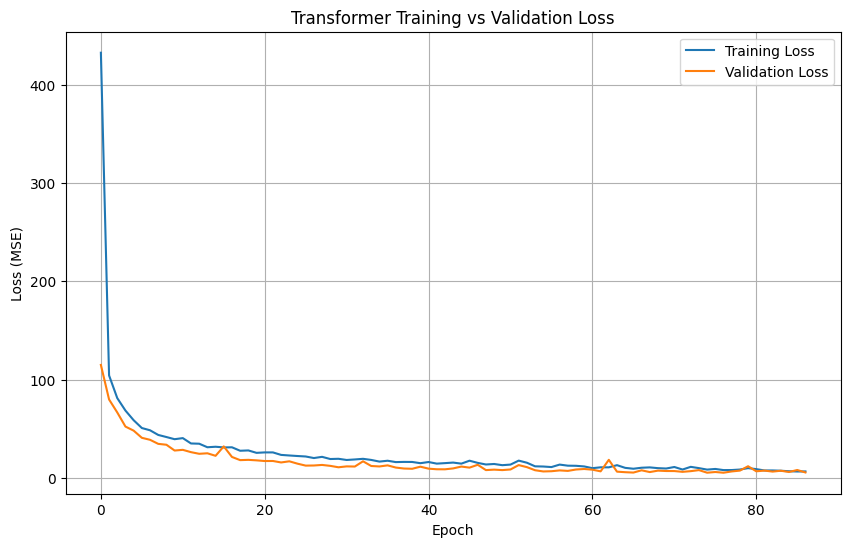

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.plot(
    history_transformer.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_transformer.history['val_loss'],
    label='Validation Loss'
)

plt.title("Transformer Training vs Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss (MSE)")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
transformer_predictions = transformer_model.predict(
    X_test
).flatten()

print("Prediction Shape:", transformer_predictions.shape)

print("\nFirst 10 Predictions:")
print(transformer_predictions[:10])

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step
Prediction Shape: (1133,)

First 10 Predictions:
[33.88552  27.233791 36.30716  11.295529 24.756733 25.963993 27.541943
 42.827034 22.57162  14.146696]


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

transformer_mae = mean_absolute_error(
    y_test,
    transformer_predictions
)

transformer_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        transformer_predictions
    )
)

transformer_r2 = r2_score(
    y_test,
    transformer_predictions
)

print("Transformer MAE :", transformer_mae)
print("Transformer RMSE:", transformer_rmse)
print("Transformer R2  :", transformer_r2)

Transformer MAE : 1.572492289263194
Transformer RMSE: 2.2892020704367764
Transformer R2  : 0.9515451271862969


## Proposed Model

In [ ]:
SEQUENCE_LENGTH = 10

X_sequences_new = []
y_sequences_new = []

for patient in scaled_df["subject#"].unique():

    patient_data = scaled_df[
        scaled_df["subject#"] == patient
    ].reset_index(drop=True)

    patient_features = patient_data.drop(
        columns=[
            "subject#",
            "total_UPDRS"
        ]
    )

    for i in range(
        len(patient_data) - SEQUENCE_LENGTH
    ):

        X_seq = patient_features.iloc[
            i:i+SEQUENCE_LENGTH
        ].values

        y_seq = patient_data.iloc[
            i+SEQUENCE_LENGTH
        ]["total_UPDRS"]

        X_sequences_new.append(X_seq)
        y_sequences_new.append(y_seq)

X_sequences_new = np.array(X_sequences_new)
y_sequences_new = np.array(y_sequences_new)

print(X_sequences_new.shape)
print(y_sequences_new.shape)

(5455, 10, 19)
(5455,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_sequences_new,
    y_sequences_new,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train_new.shape)
print("X_test :", X_test_new.shape)
print("y_train:", y_train_new.shape)
print("y_test :", y_test_new.shape)

X_train: (4364, 10, 19)
X_test : (1091, 10, 19)
y_train: (4364,)
y_test : (1091,)


In [ ]:
import numpy as np

SAVE_PATH = "/content/drive/MyDrive/Parkinson_Transformer_Project/processed_data/"

np.save(SAVE_PATH + "X_train_faett.npy", X_train_new)
np.save(SAVE_PATH + "X_test_faett.npy", X_test_new)

np.save(SAVE_PATH + "y_train_faett.npy", y_train_new)
np.save(SAVE_PATH + "y_test_faett.npy", y_test_new)

print("FAETT dataset saved successfully.")

FAETT dataset saved successfully.


In [ ]:
import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D,
    Multiply
)

from tensorflow.keras.models import Model

print("FAETT libraries loaded successfully.")

FAETT libraries loaded successfully.


In [ ]:
def feature_attention_block(inputs):

    # Learn feature importance scores

    attention_weights = Dense(
        19,
        activation='sigmoid',
        name='feature_attention'
    )(inputs)

    attended_features = Multiply()(
        [inputs, attention_weights]
    )

    return attended_features

print("Feature Attention Block Created")

Feature Attention Block Created


In [ ]:
from tensorflow.keras.layers import Embedding

def add_positional_encoding(inputs):

    seq_len = inputs.shape[1]      # 10
    d_model = inputs.shape[2]      # 19

    positions = tf.range(
        start=0,
        limit=seq_len,
        delta=1
    )

    position_embedding = Embedding(
        input_dim=seq_len,
        output_dim=d_model,
        name="position_embedding"
    )(positions)

    return inputs + position_embedding

print("Positional Encoding Layer Created")

Positional Encoding Layer Created


In [ ]:
def transformer_encoder_faett(
    inputs,
    head_size=64,
    num_heads=8,
    ff_dim=256,
    dropout=0.2
):

    # Multi-Head Self Attention

    attention_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=head_size
    )(inputs, inputs)

    attention_output = Dropout(
        dropout
    )(attention_output)

    x = LayerNormalization(
        epsilon=1e-6
    )(inputs + attention_output)

    # Feed Forward Network

    ff = Dense(
        ff_dim,
        activation="relu"
    )(x)

    ff = Dropout(
        dropout
    )(ff)

    ff = Dense(
        inputs.shape[-1]
    )(ff)

    output = LayerNormalization(
        epsilon=1e-6
    )(x + ff)

    return output

print("FAETT Transformer Encoder Created")

FAETT Transformer Encoder Created


In [ ]:
inputs = Input(shape=(10, 19))

# Feature Attention Layer
x = feature_attention_block(inputs)

# Positional Encoding
x = add_positional_encoding(x)

# Transformer Encoder Block 1
x = transformer_encoder_faett(
    x,
    head_size=64,
    num_heads=8,
    ff_dim=256,
    dropout=0.2
)

# Transformer Encoder Block 2
x = transformer_encoder_faett(
    x,
    head_size=64,
    num_heads=8,
    ff_dim=256,
    dropout=0.2
)

# Transformer Encoder Block 3
x = transformer_encoder_faett(
    x,
    head_size=64,
    num_heads=8,
    ff_dim=256,
    dropout=0.2
)

# Pooling
x = GlobalAveragePooling1D()(x)

# Enhanced Regression Head

x = Dense(
    128,
    activation='relu'
)(x)

x = Dropout(0.3)(x)

x = Dense(
    64,
    activation='relu'
)(x)

x = Dropout(0.2)(x)

x = Dense(
    32,
    activation='relu'
)(x)

outputs = Dense(1)(x)

faett_model = Model(
    inputs=inputs,
    outputs=outputs
)

faett_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 10, 19)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_attention   │ (None, 10, 19)    │        380 │ input_layer_3[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 10, 19)    │          0 │ input_layer_3[0]… │
│                     │                   │            │ feature_attentio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 10, 19)    │          0 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 10, 19)    │     40,467 │ add_4[0][0],      │
│ (MultiHeadAttentio… │                   │            │ add_4[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 10, 19)    │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 10, 19)    │          0 │ add_4[0][0],      │
│                     │                   │            │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 19)    │         38 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 10, 256)   │      5,120 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 10, 256)   │          0 │ dense_11[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 10, 19)    │      4,883 │ dropout_13[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 10, 19)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 19)    │         38 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 10, 19)    │     40,467 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_15          │ (None, 10, 19)    │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 10, 19)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_15[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 19)    │         38 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 10, 256)   │      5,120 │ layer_normalizat

 Total params: 164,947 (644.32 KB)

 Trainable params: 164,947 (644.32 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
faett_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("FAETT model compiled successfully.")

FAETT model compiled successfully.


In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

faett_checkpoint_path = (
    "/content/drive/MyDrive/Parkinson_Transformer_Project/models/best_faett.keras"
)

faett_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

faett_checkpoint = ModelCheckpoint(
    filepath=faett_checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

print("FAETT callbacks configured successfully.")

FAETT callbacks configured successfully.


In [ ]:
history_faett = faett_model.fit(

    X_train_new,
    y_train_new,

    validation_split=0.2,

    epochs=150,

    batch_size=32,

    callbacks=[
        faett_early_stop,
        faett_checkpoint
    ],

    verbose=1
)

print("FAETT training completed.")

Epoch 1/150
109/110 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 616.9882 - mae: 21.1862
Epoch 1: val_loss improved from None to 97.02663, saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_faett.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_faett.keras
110/110 ━━━━━━━━━━━━━━━━━━━━ 16s 60ms/step - loss: 338.5088 - mae: 14.4673 - val_loss: 97.0266 - val_mae: 8.1435
Epoch 2/150
109/110 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 104.4931 - mae: 8.2795
Epoch 2: val_loss improved from 97.02663 to 69.53365, saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_faett.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Parkinson_Transformer_Project/models/best_faett.keras
110/110 ━━━━━━━━━━━━━━━━━━━━ 8s 70ms/step - loss: 95.8273 - mae: 7.8600 - val_loss: 69.5337 - val_mae: 6.8404
Epoch 3/150
109/110 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 86.3924 - mae: 7.3827
Epoch 3:

In [ ]:
faett_predictions = faett_model.predict(
    X_test_new
).flatten()

print("Prediction Shape:", faett_predictions.shape)

print("\nFirst 10 Predictions:")
print(faett_predictions[:10])

35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step
Prediction Shape: (1091,)

First 10 Predictions:
[25.222298 42.490902 46.80486  11.527845 22.012602 24.645134 32.586983
 34.563114 25.463987 52.750965]


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

faett_mae = mean_absolute_error(
    y_test_new,
    faett_predictions
)

faett_rmse = np.sqrt(
    mean_squared_error(
        y_test_new,
        faett_predictions
    )
)

faett_r2 = r2_score(
    y_test_new,
    faett_predictions
)

print("FAETT MAE :", faett_mae)
print("FAETT RMSE:", faett_rmse)
print("FAETT R2  :", faett_r2)

FAETT MAE : 1.268768995017551
FAETT RMSE: 1.6456506072397032
FAETT R2  : 0.9753852257111891


## Plot

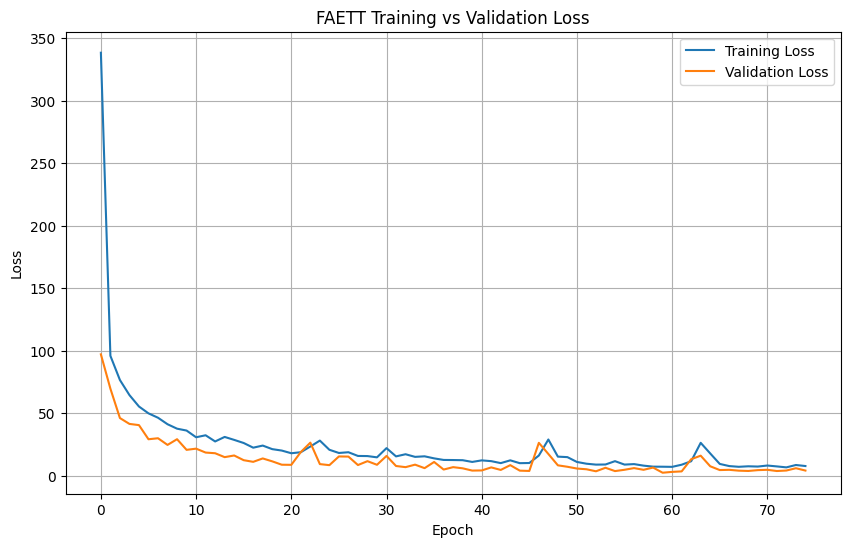

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(history_faett.history['loss'],
         label='Training Loss')

plt.plot(history_faett.history['val_loss'],
         label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('FAETT Training vs Validation Loss')

plt.legend()
plt.grid(True)
plt.show()

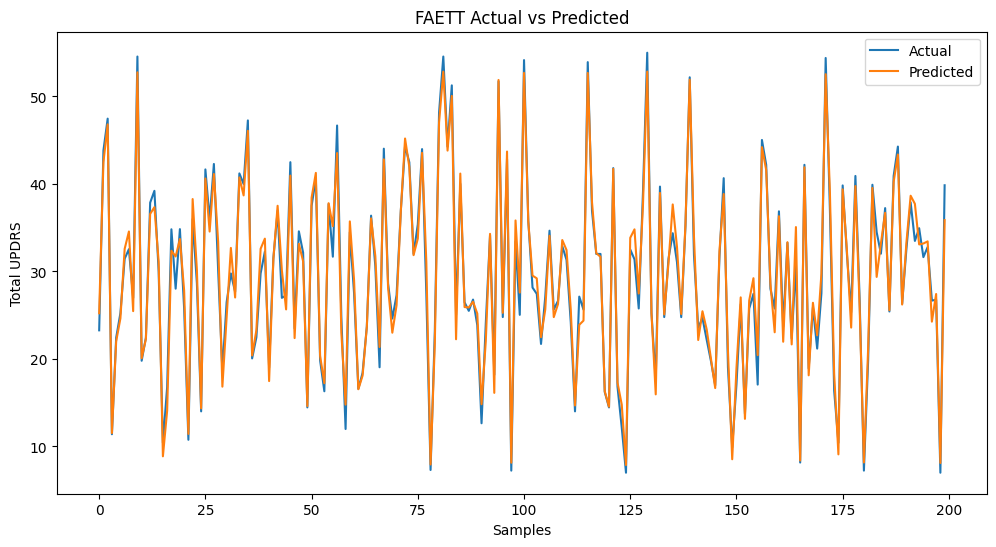

In [ ]:
plt.figure(figsize=(12,6))

plt.plot(y_test_new[:200],
         label='Actual')

plt.plot(faett_predictions[:200],
         label='Predicted')

plt.title('FAETT Actual vs Predicted')
plt.xlabel('Samples')
plt.ylabel('Total UPDRS')

plt.legend()
plt.show()

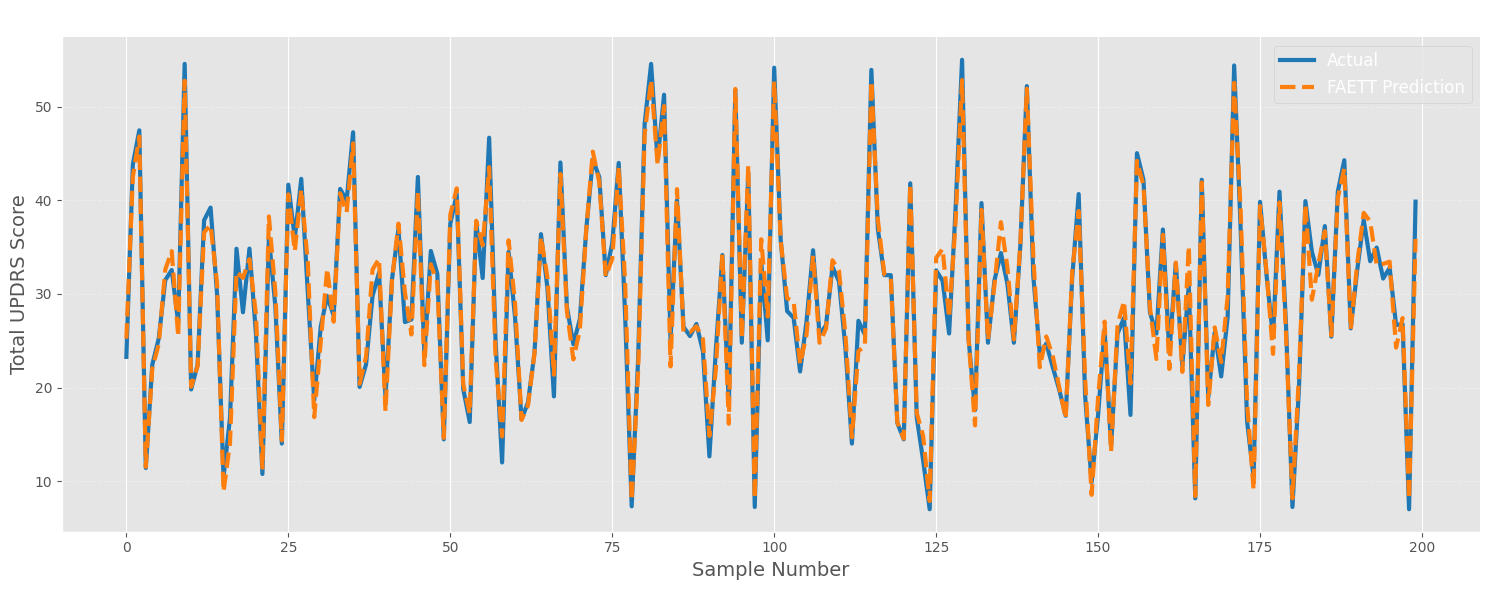

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))

# Actual Values - Black
plt.plot(
    y_test_new[:200],
    color='#1f77b4',
    linewidth=3,
    label='Actual'
)

plt.plot(
    faett_predictions[:200],
    color='#ff7f0e',
    linewidth=3,
    linestyle='--',
    label='FAETT Prediction'
)

plt.title(
    'Actual vs Predicted Total UPDRS Scores',
    fontsize=18,
    fontweight='bold'
)

plt.xlabel('Sample Number', fontsize=14)
plt.ylabel('Total UPDRS Score', fontsize=14)

plt.legend(fontsize=12)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

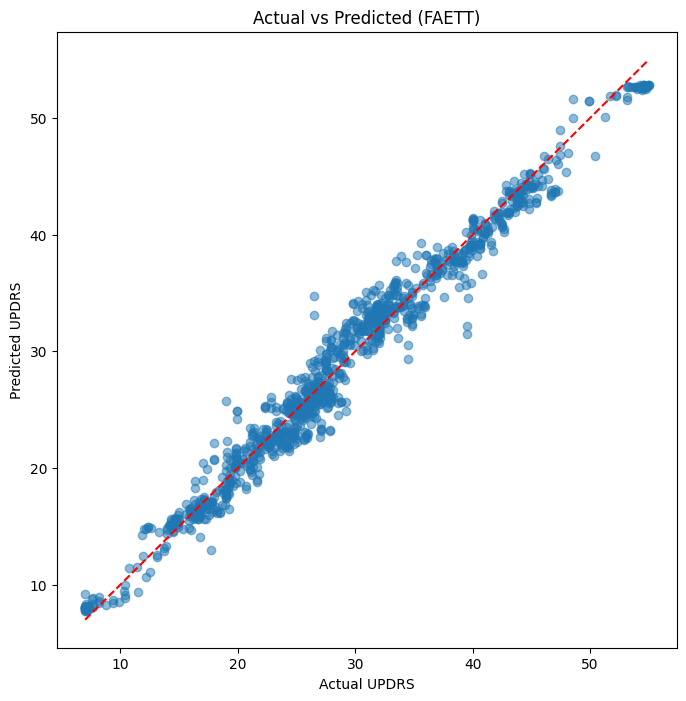

In [ ]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_test_new,
    faett_predictions,
    alpha=0.5
)

plt.plot(
    [y_test_new.min(), y_test_new.max()],
    [y_test_new.min(), y_test_new.max()],
    'r--'
)

plt.xlabel('Actual UPDRS')
plt.ylabel('Predicted UPDRS')
plt.title('Actual vs Predicted (FAETT)')

plt.show()

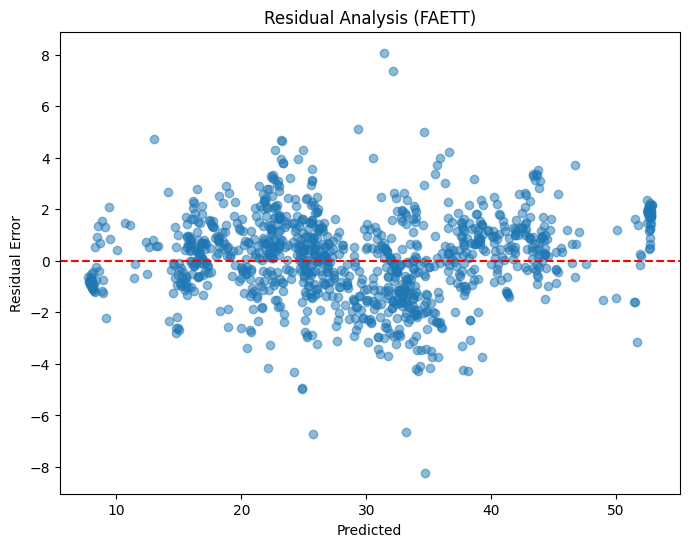

In [ ]:
residuals = y_test_new - faett_predictions

plt.figure(figsize=(8,6))

plt.scatter(
    faett_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel('Predicted')
plt.ylabel('Residual Error')
plt.title('Residual Analysis (FAETT)')

plt.show()

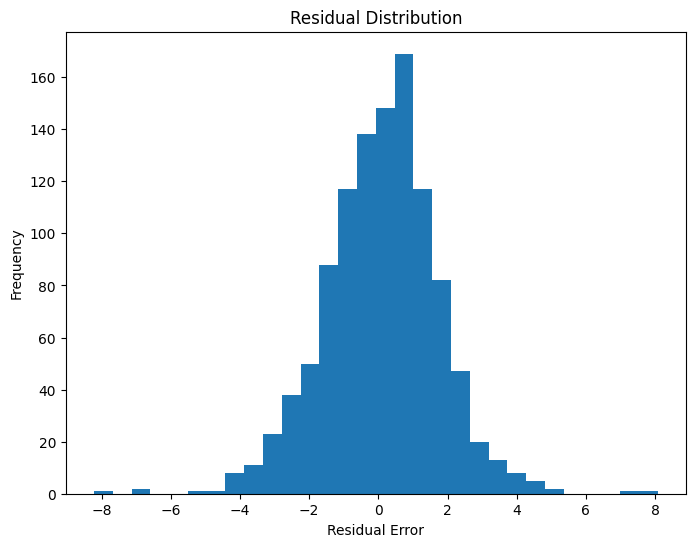

In [ ]:
plt.figure(figsize=(8,6))

plt.hist(
    residuals,
    bins=30
)

plt.xlabel('Residual Error')
plt.ylabel('Frequency')
plt.title('Residual Distribution')

plt.show()

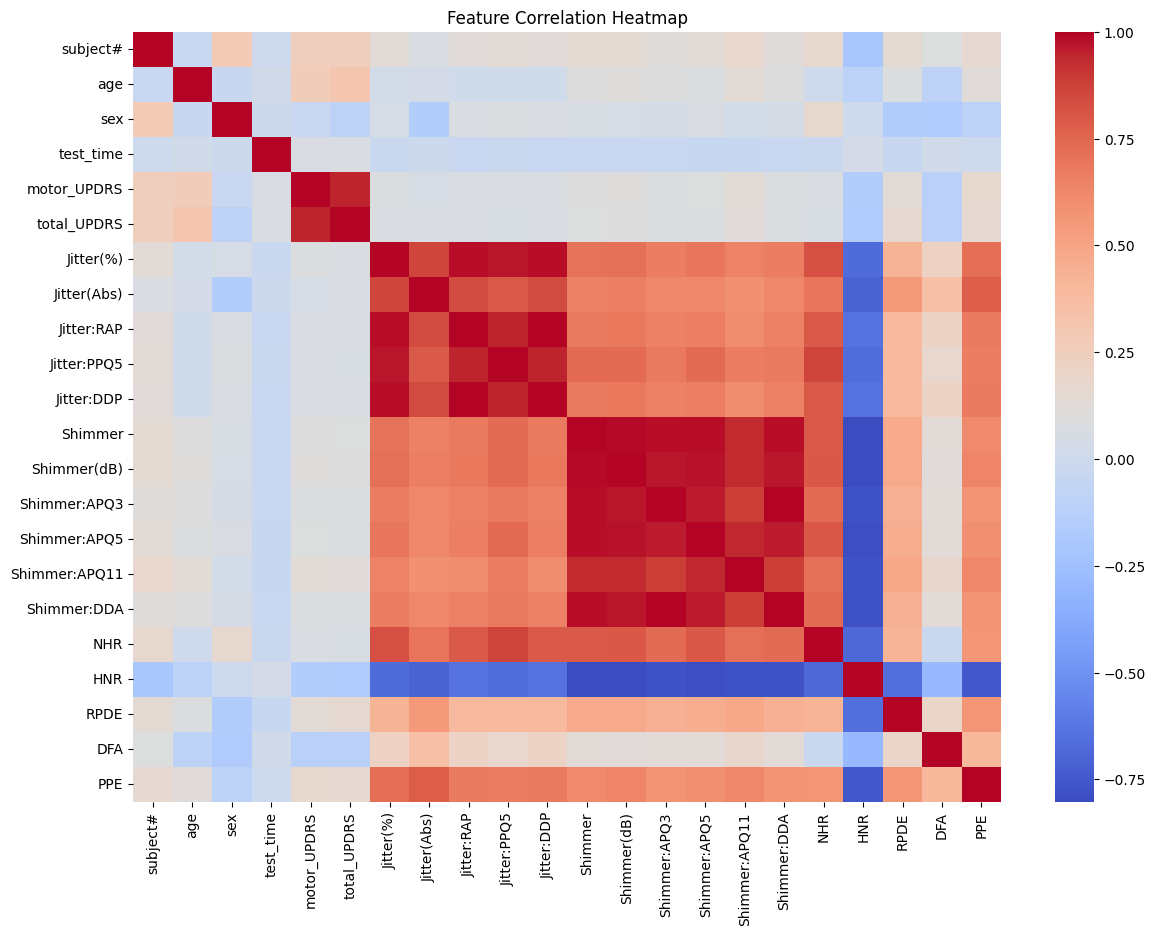

In [ ]:
import seaborn as sns

plt.figure(figsize=(14,10))

sns.heatmap(
    df.corr(),
    cmap='coolwarm'
)

plt.title('Feature Correlation Heatmap')
plt.show()

## SHAP

In [ ]:
import numpy as np

# Remove output dimension

shap_values_3d = shap_values.squeeze(-1)

print(shap_values_3d.shape)

(50, 10, 19)


In [ ]:
shap_values_agg = np.mean(
    np.abs(shap_values_3d),
    axis=1
)

print(shap_values_agg.shape)

(50, 19)


In [ ]:
X_shap = X_test_new[:50].mean(axis=1)

print(X_shap.shape)

(50, 19)


In [ ]:
feature_names = [
    'age',
    'sex',
    'test_time',
    'motor_UPDRS',
    'Jitter(%)',
    'Jitter(Abs)',
    'Jitter:RAP',
    'Jitter:PPQ5',
    'Jitter:DDP',
    'Shimmer',
    'Shimmer(dB)',
    'Shimmer:APQ3',
    'Shimmer:APQ5',
    'Shimmer:APQ11',
    'Shimmer:DDA',
    'NHR',
    'HNR',
    'RPDE',
    'DFA'
]

/tmp/ipykernel_1605/1213172900.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


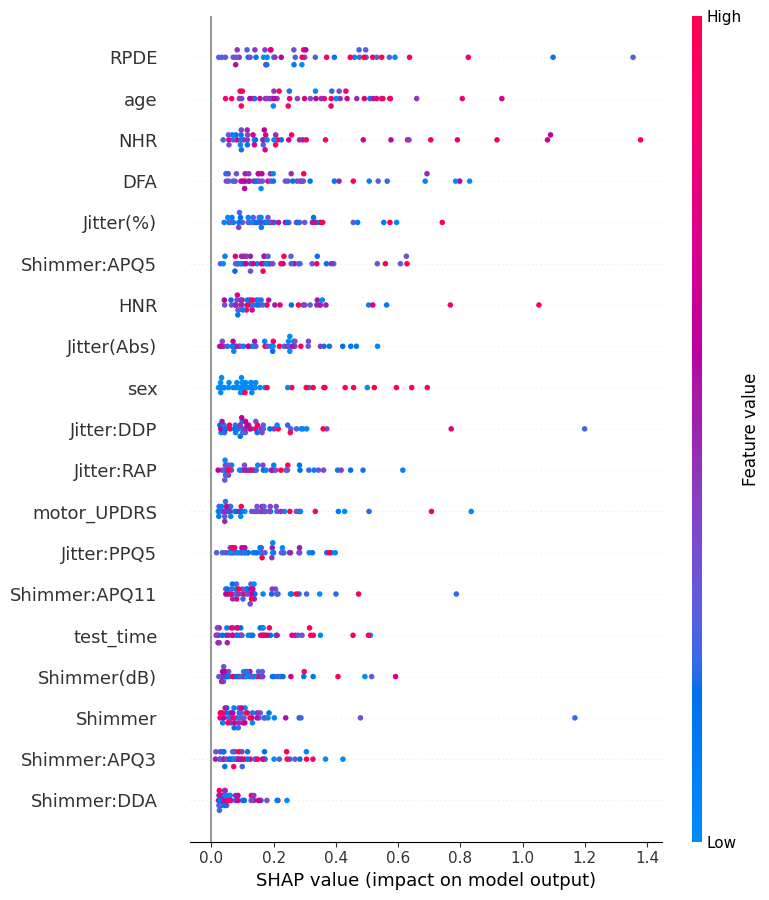

In [ ]:
shap.summary_plot(
    shap_values_agg,
    X_shap,
    feature_names=feature_names
)

/tmp/ipykernel_1605/666658235.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


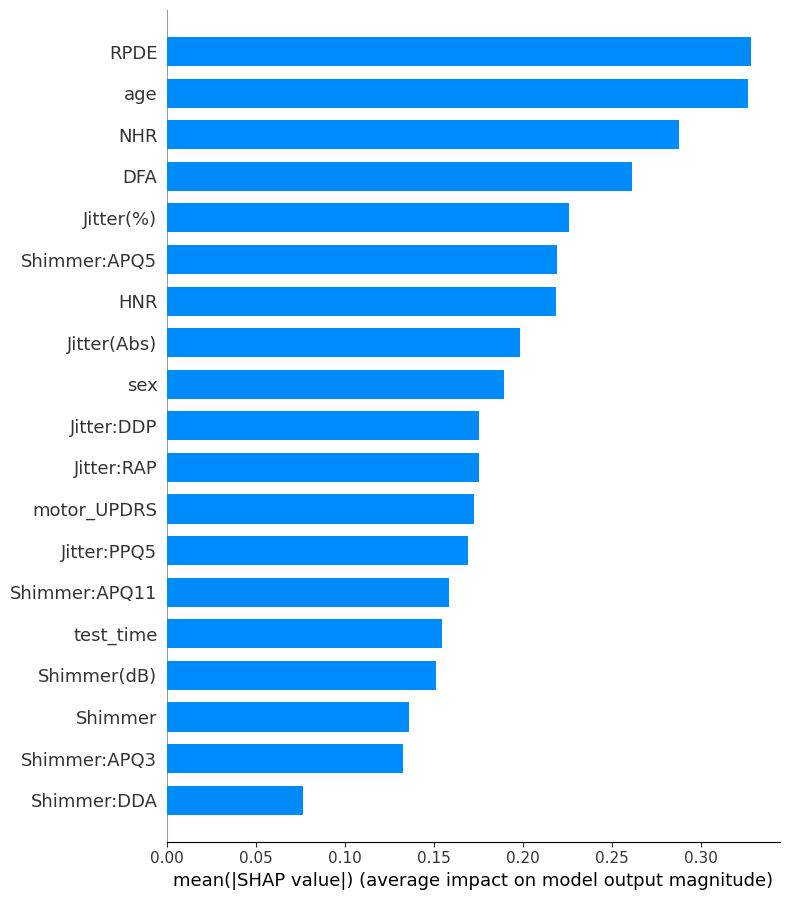

In [ ]:
shap.summary_plot(
    shap_values_agg,
    X_shap,
    feature_names=feature_names,
    plot_type="bar"
)

In [ ]:
history_lstm_df = pd.DataFrame(history_lstm.history)

history_lstm_df.to_csv(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/lstm_history.csv",
    index=False
)

In [ ]:
history_transformer_df = pd.DataFrame(
    history_transformer.history
)

history_transformer_df.to_csv(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/transformer_history.csv",
    index=False
)

In [ ]:
history_faett_df = pd.DataFrame(
    history_faett.history
)

history_faett_df.to_csv(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/faett_history.csv",
    index=False
)

In [ ]:
faett_results = pd.DataFrame({
    "Actual": y_test_new,
    "Predicted": faett_predictions
})

faett_results.to_csv(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/faett_predictions.csv",
    index=False
)

print("FAETT predictions saved.")

FAETT predictions saved.


In [ ]:
comparison_df = pd.DataFrame({

    "Model": [
        "Random Forest",
        "LSTM",
        "Transformer",
        "FAETT"
    ],

    "MAE": [
        rf_mae,
        lstm_mae,
        transformer_mae,
        faett_mae
    ],

    "RMSE": [
        rf_rmse,
        lstm_rmse,
        transformer_rmse,
        faett_rmse
    ],

    "R2": [
        rf_r2,
        lstm_r2,
        transformer_r2,
        faett_r2
    ]
})

comparison_df.to_csv(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/model_comparison.csv",
    index=False
)

comparison_df

,Model,MAE,RMSE,R2
0,Random Forest,1.115423,1.773536,0.970916
1,LSTM,1.499182,2.644474,0.935338
2,Transformer,1.572492,2.289202,0.951545
3,FAETT,1.268769,1.645651,0.975385


In [ ]:
np.save(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/shap_values.npy",
    shap_values
)

In [ ]:
shap_values = np.load(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/results/shap_values.npy"
)

In [ ]:
np.save(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/processed_data/X_train.npy",
    X_train
)

np.save(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/processed_data/X_test.npy",
    X_test
)

np.save(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/processed_data/y_train.npy",
    y_train
)

np.save(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/processed_data/y_test.npy",
    y_test
)

In [ ]:
from tensorflow.keras.models import load_model

faett_model = load_model(
    "/content/drive/MyDrive/Parkinson_Transformer_Project/models/best_faett.keras"
)